# WaZP Stacked ΔΣ → Masses → Mass–Richness Relation

18 stacks (3 z × 6 NGALS), no Δm partition.

Pipeline:

1. Load WaZP real-data catalog + metacal source pre-filter + BallTree (§1).
2. Bin definitions — 3 fixed z slices × 6 fixed-edge log-spaced richness slices (§2).
3. Per-cluster `bkg` arrays (reused from `data/wazp_bkgs.pkl` if available, otherwise computed in parallel) (§3).
4. Stack each of the 18 (z, NGALS) cells via `xlensing.data.stacked_signal` (§4).
5. Plot the 18 profiles grouped by redshift, with 6 richness curves per panel (§5).
6. Fit each stack with the **full** `xlensing.model.NFW_Delta_Sigma` (centered NFW + miscentered NFW + BCG + 2-halo), with free `log10(M)`, `C`, `FMISS`, `SIGMA_OFF` (BCG mass fixed at 0). Posterior via `nautilus` (§6).
7. Overlay best-fit models on the stack profiles (§7).
8. Fit a power-law mass–richness relation

   $$\log_{10} M_{200m} \;=\; \log_{10} M_0 \;+\; \alpha\,\log_{10}(\lambda/\lambda_{\rm piv}) \;+\; \beta\,\log_{10}((1+z)/(1+z_{\rm piv}))$$

   plus a per-z-bin 1D fit (§8) and a final M–λ plot (§9).

In [ ]:
import os, time, pickle, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.cosmology import Planck18 as COSMO
from astropy import units as u
from sklearn.neighbors import BallTree
from multiprocess import Pool, cpu_count
from nautilus import Prior, Sampler
import xlensing.data
import xlensing.model
warnings.filterwarnings('ignore')

WAZP_REAL    = 'data/wazp_real_data.fits'
FILTERED_NPZ = 'data/metacal_filtered.npz'
BKG_CACHE    = 'data/wazp_bkgs.pkl'
STACKS_PKL   = 'data/wazp_mass_richness_stacks.pkl'
FITS_PKL     = 'data/wazp_mass_richness_fits.pkl'

USE_CACHE  = True         # set to False to force a clean rebuild of every intermediate
RADIUS_MPC = 5.0
NBOOT      = 500
NLIVE      = 400          # nautilus live points per fit
NWORKERS   = 15#max(1, cpu_count())

# Radial bins (Mpc) — same convention as the other notebooks
radii  = np.logspace(-0.6, 0.6, 8)
_N     = len(radii)
_edges = np.logspace(
    np.log10(radii[0])   + (np.log10(radii[0]) - np.log10(radii[1])) / 2,
    np.log10(radii[-1])  - (np.log10(radii[0]) - np.log10(radii[1])) / 2,
    _N + 1,
)
BINS_LIMS = np.array([[_edges[i], _edges[i+1]] for i in range(_N)])

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
os.makedirs('data', exist_ok=True)

print(f'USE_CACHE = {USE_CACHE}')
print(f'NWORKERS  = {NWORKERS}')
print(f'NBOOT     = {NBOOT}')
print(f'NLIVE     = {NLIVE}')

## 1 — Load catalogs and build the BallTree

In [2]:
wazp = Table.read(WAZP_REAL)
print(f'Loaded {len(wazp):,} clusters from {WAZP_REAL}')

if not os.path.exists(FILTERED_NPZ):
    raise FileNotFoundError(
        f'{FILTERED_NPZ} not found. Run wazp_lensing_signals.ipynb §2 first.'
    )
f = np.load(FILTERED_NPZ)
SR_RA  = f['ra'];  SR_DEC = f['dec']; SR_Z = f['z']
SR_E1  = f['e1'];  SR_E2  = f['e2'];  SR_W = f['w']
SR_R11 = f['R11']; SR_R12 = f['R12']
SR_R21 = f['R21']; SR_R22 = f['R22']
print(f'Loaded {len(SR_RA):,} pre-filtered sources')

t0 = time.time()
TREE = BallTree(np.column_stack([SR_DEC, SR_RA]), metric='haversine')
print(f'BallTree built in {time.time()-t0:.1f}s')

Loaded 15,967 clusters from data/wazp_real_data.fits
Loaded 126,719,902 pre-filtered sources
BallTree built in 73.8s


## 2 — Bin definitions

- **z** (fixed): `[0.10, 0.35, 0.55, 0.70]`
- **NGALS** (fixed, 6 bins, log-spaced from 25 to 200 with a tail to ∞):
  `[25, 37.9, 57.4, 87.1, 132.2, 200.0, ∞]`

In [3]:
z_edges  = np.array([0.10, 0.35, 0.55, 0.70])
ng_edges = np.concatenate([np.geomspace(25.0, 200.0, 6), [np.inf]])
print(f'z_edges  = {z_edges}')
print(f'ng_edges = {np.round(ng_edges, 2)}')

def bin_idx(values, edges):
    v   = np.asarray(values, dtype=float)
    idx = np.digitize(v, edges[1:-1], right=False)
    out = ~((v >= edges[0]) & (v <= edges[-1]))
    idx[out] = -1
    return idx

z_bin  = bin_idx(wazp['ZPHOT'], z_edges)
ng_bin = bin_idx(wazp['NGALS'], ng_edges)

print('\nCell populations:')
print(f'{"cell":>6}  {"z":>14}  {"NGALS":>16}  {"N":>9}  '
      f'{"⟨z⟩":>6}  {"⟨λ⟩":>7}')
print('-' * 75)
for i in range(3):
    for j in range(6):
        cell = (z_bin == i) & (ng_bin == j)
        if not cell.any():
            continue
        zm  = float(np.mean(np.asarray(wazp['ZPHOT'])[cell]))
        lm  = float(np.mean(np.asarray(wazp['NGALS'])[cell]))
        hi  = (f'{ng_edges[j+1]:.1f}'
               if np.isfinite(ng_edges[j+1]) else 'inf')
        print(f'{"("+str(i)+","+str(j)+")":>6}  '
              f'[{z_edges[i]:.2f},{z_edges[i+1]:.2f}){" ":>3}  '
              f'[{ng_edges[j]:.1f},{hi}){" ":>3}  '
              f'{int(cell.sum()):>9,}  {zm:>6.3f}  {lm:>7.2f}')

z_edges  = [0.1  0.35 0.55 0.7 ]
ng_edges = [ 25.    37.89  57.43  87.06 131.95 200.      inf]

Cell populations:
  cell               z             NGALS          N     ⟨z⟩      ⟨λ⟩
---------------------------------------------------------------------------
 (0,0)  [0.10,0.35)     [25.0,37.9)         1,450   0.262    30.25
 (0,1)  [0.10,0.35)     [37.9,57.4)           689   0.271    45.86
 (0,2)  [0.10,0.35)     [57.4,87.1)           329   0.272    69.29
 (0,3)  [0.10,0.35)     [87.1,132.0)           101   0.270   102.92
 (0,4)  [0.10,0.35)     [132.0,200.0)            38   0.284   155.40
 (0,5)  [0.10,0.35)     [200.0,inf)             6   0.284   239.18
 (1,0)  [0.35,0.55)     [25.0,37.9)         4,570   0.451    30.24
 (1,1)  [0.35,0.55)     [37.9,57.4)         2,014   0.449    45.69
 (1,2)  [0.35,0.55)     [57.4,87.1)           870   0.446    68.62
 (1,3)  [0.35,0.55)     [87.1,132.0)           266   0.439   103.57
 (1,4)  [0.35,0.55)     [132.0,200.0)            70   0.435   156.0

## 3 — Per-cluster `bkg` arrays

Reuses `data/wazp_bkgs.pkl` if present; otherwise runs `bkg_worker` in parallel to build it.

In [4]:
def bkg_worker(row):
    try:
        cid   = int(row['ID'])
        z_cl  = float(row['ZPHOT'])
        ra_r  = np.deg2rad(float(row['RA']))
        dec_r = np.deg2rad(float(row['DEC']))

        D_A = float(COSMO.angular_diameter_distance(z_cl).to_value(u.Mpc))
        if D_A <= 0:
            return {'ID': cid, 'error': f'D_A={D_A}'}
        ang_r = RADIUS_MPC / D_A

        idx = TREE.query_radius(np.array([[dec_r, ra_r]]), r=ang_r)[0]
        if len(idx) == 0:
            return {'ID': cid, 'bkg': None, 'count': 0}

        sources = (
            SR_RA [idx], SR_DEC[idx], SR_Z [idx],
            SR_E1 [idx], SR_E2 [idx], SR_W [idx],
            SR_R11[idx], SR_R12[idx], SR_R21[idx], SR_R22[idx],
        )
        res = xlensing.data.metacal_cluster_lensing(
            (ra_r, dec_r, z_cl), sources, radius=RADIUS_MPC,
        )
        if res['Count'] == 0:
            return {'ID': cid, 'bkg': None, 'count': 0}
        bkg = np.array([
            np.asarray(res['Critical Density'], dtype='float32'),
            np.asarray(res['Tangential Shear'], dtype='float32'),
            np.asarray(res['Cross Shear'],      dtype='float32'),
            np.asarray(res['Weights'],          dtype='float32'),
            np.asarray(res['Radial Distance'],  dtype='float32'),
            np.asarray(res['Mult. Bias'],       dtype='float32'),
        ])
        return {'ID': cid, 'bkg': bkg, 'count': int(res['Count'])}
    except Exception as exc:
        return {'ID': int(row.get('ID', -1)), 'error': repr(exc)}

In [ ]:
if os.path.exists(BKG_CACHE) and USE_CACHE:
    with open(BKG_CACHE, 'rb') as fh:
        bkg_results = pickle.load(fh)
    print(f'Loaded {len(bkg_results):,} cached bkgs from {BKG_CACHE}')
else:
    if os.path.exists(BKG_CACHE):
        print(f'USE_CACHE = False, rebuilding {BKG_CACHE} from scratch')
    input_list = [
        {'ID': int(wazp['ID'][i]),    'RA':   float(wazp['RA'][i]),
         'DEC':float(wazp['DEC'][i]), 'ZPHOT':float(wazp['ZPHOT'][i])}
        for i in range(len(wazp))
    ]
    print(f'Computing bkgs for {len(input_list):,} clusters with {NWORKERS} workers')
    bkg_results = []
    t0 = time.time()
    with Pool(NWORKERS) as pool:
        for i, r in enumerate(pool.imap_unordered(
                bkg_worker, input_list, chunksize=4)):
            bkg_results.append(r)
            if (i + 1) % 200 == 0 or (i + 1) == len(input_list):
                dt  = time.time() - t0
                eta = dt * (len(input_list) - i - 1) / (i + 1)
                print(f'  {i+1:>6,}/{len(input_list):,}  '
                      f'elapsed {dt/60:5.1f} min  eta {eta/60:5.1f} min',
                      flush=True)
    with open(BKG_CACHE, 'wb') as fh:
        pickle.dump(bkg_results, fh)

bkg_by_id = {r['ID']: r['bkg'] for r in bkg_results
             if r.get('bkg') is not None}
print(f'Usable bkgs: {len(bkg_by_id):,}')

## 4 — Stack the 18 (z, NGALS) cells

In [ ]:
def collect_bkgs(mask):
    ids = np.asarray(wazp['ID'])[mask]
    return [bkg_by_id[int(i)] for i in ids if int(i) in bkg_by_id]

# Note: xlensing.data.stacked_signal now returns the boost-corrected ΔΣ
# (sigmas already = boost*ΔΣ_raw) and its full covariance with boost
# uncertainty propagated from a joint cluster bootstrap.  No manual
# multiplication needed.
stacks = {}
boost_outer = []
for i in range(3):
    for j in range(6):
        name = f'z{i}_ng{j}'
        mask = (z_bin == i) & (ng_bin == j)
        if not mask.any():
            continue
        bkgs = collect_bkgs(mask)
        if not bkgs:
            continue
        t0 = time.time()
        sigmas, boosts, boosts_cov, sigmas_cov, xigmas, xigmas_cov = (
            xlensing.data.stacked_signal(bkgs, BINS_LIMS, NBOOT)
        )

        cell_z   = np.asarray(wazp['ZPHOT'])[mask]
        cell_lam = np.asarray(wazp['NGALS'])[mask]
        stacks[name] = {
            'z_bin':     i, 'ng_bin': j,
            'z_lo':      float(z_edges[i]),  'z_hi':  float(z_edges[i+1]),
            'ng_lo':     float(ng_edges[j]), 'ng_hi': float(ng_edges[j+1]),
            'z_mean':    float(cell_z.mean()),
            'lambda_mean': float(cell_lam.mean()),
            'n_stacked': len(bkgs),
            'sigmas':     np.asarray(sigmas),
            'sigmas_cov': np.asarray(sigmas_cov),
            'boosts':     np.asarray(boosts),
            'boosts_cov': np.asarray(boosts_cov),
            'xigmas':     np.asarray(xigmas),
            'xigmas_cov': np.asarray(xigmas_cov),
        }
        b_err_outer = float(np.sqrt(boosts_cov[-1, -1]))
        boost_outer.append((name, float(boosts[-1]), b_err_outer))
        print(f'{name}: ⟨z⟩={cell_z.mean():.3f}  '
              f'⟨λ⟩={cell_lam.mean():6.2f}  N={len(bkgs):,}  '
              f'B_outer={boosts[-1]:.3f}±{b_err_outer:.3f}  '
              f'({time.time()-t0:.1f}s)')

b_outer = np.array([v for _, v, _ in boost_outer])
print(f'\nOuter-bin boost factor over {len(boost_outer)} stacks:')
print(f'  median = {np.median(b_outer):.3f}  mean = {b_outer.mean():.3f}  '
      f'min = {b_outer.min():.3f}  max = {b_outer.max():.3f}')
if not (0.85 < np.median(b_outer) < 1.15):
    print('  WARNING: outer-bin boost median far from 1 — check binning / random count')

with open(STACKS_PKL, 'wb') as fh:
    pickle.dump({'radii': radii, 'bins_lims': BINS_LIMS,
                 'z_edges': z_edges, 'ng_edges': ng_edges,
                 'stacks': stacks}, fh)
print(f'\nProduced {len(stacks)}/18 stacks, saved to {STACKS_PKL}')

### 4.1 — Boost-factor diagnostic

Boost factors $B(R)$ correct ΔΣ for cluster-member contamination of the source catalog ($\DS_{\rm corr}=B\cdot\DS_{\rm raw}$, already applied above). A correctly-behaved boost is $> 1$ at small $R$ (member dilution) and approaches 1 at large $R$ where the cluster has no influence. The plot below overlays $B(R)$ for all 18 stacks, grouped by $z$ slice; the horizontal line at $B=1$ is the asymptote.

In [ ]:
import matplotlib as mpl
ng_cmap   = mpl.cm.viridis
ng_colors = [ng_cmap(x) for x in np.linspace(0.0, 0.95, 6)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for i in range(3):
    ax = axes[i]
    for j in range(6):
        name = f'z{i}_ng{j}'
        if name not in stacks: continue
        s   = stacks[name]
        hi  = (f'{s["ng_hi"]:.0f}'
               if np.isfinite(s["ng_hi"]) else r'\infty')
        b_err = np.sqrt(np.diag(s['boosts_cov']))
        ax.errorbar(radii, s['boosts'], yerr=b_err,
                    fmt='o-', ms=4, capsize=2.5, color=ng_colors[j],
                    label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                           f'N={s["n_stacked"]:,}'))
    ax.axhline(1.0, color='k', lw=1.0, ls='--', alpha=0.6)
    ax.set_xscale('log')
    ax.set_xlabel(r'$R$  [Mpc]')
    if i == 0:
        ax.set_ylabel(r'Boost factor $B(R)$')
    ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$', fontsize=11)
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=7, loc='upper right')
plt.suptitle('Boost factors per stack with bootstrap errors (should → 1 at outer $R$)',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 5 — Stacked profiles grouped by redshift

Three panels, one per z slice. Within each panel the six richness curves are overlaid (color gradient by richness).

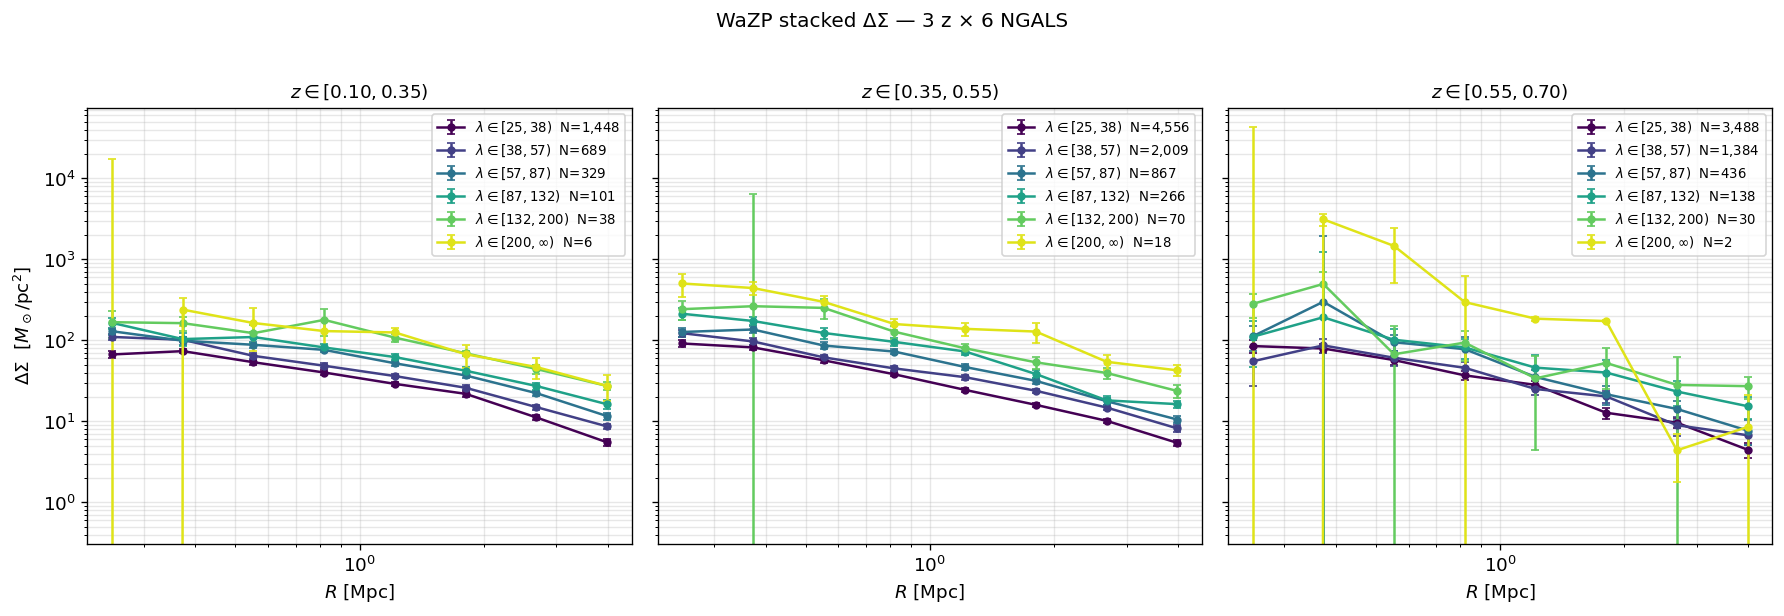

In [7]:
import matplotlib as mpl
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
cmap   = mpl.cm.viridis
colors = [cmap(x) for x in np.linspace(0.0, 0.95, 6)]

for i in range(3):
    ax = axes[i]
    for j in range(6):
        name = f'z{i}_ng{j}'
        if name not in stacks: continue
        s   = stacks[name]
        err = np.sqrt(np.diag(s['sigmas_cov']))
        hi  = (f'{s["ng_hi"]:.0f}'
               if np.isfinite(s["ng_hi"]) else r'\infty')
        ax.errorbar(
            radii, s['sigmas'], yerr=err,
            fmt='o-', ms=4, capsize=2.5, color=colors[j],
            label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                   f'N={s["n_stacked"]:,}'),
        )
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$R$ [Mpc]')
    ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$', fontsize=11)
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=8, loc='upper right')
axes[0].set_ylabel(r'$\Delta\Sigma$  [$M_\odot/\mathrm{pc}^2$]')
plt.suptitle('WaZP stacked ΔΣ — 3 z × 6 NGALS', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 6 — NFW + miscentering fits with nautilus

Model = `xlensing.model.NFW_Delta_Sigma`. Free parameters:

- `log10(M200m)` ∈ [13, 16]
- `C200m` ∈ [1, 15]
- `FMISS` ∈ [0, 1]
- `SIGMA_OFF` ∈ [0.01, 1.0]  Mpc

`BCG_B_MASS` is fixed at 0 (no central baryonic component). The redshift of the stack is set to its mean.

We use the bootstrap covariance from `stacked_signal` (added a small diagonal jitter for numerical conditioning) and the **full** `Signal` (centered NFW + miscentered NFW + BCG + 2-halo).

In [8]:
def make_loglike(data, cov, radii, z_eff):
    cov_reg = cov + 1e-6 * np.eye(len(data)) * np.mean(np.diag(cov))
    cov_inv = np.linalg.inv(cov_reg)
    def loglike(p):
        try:
            M = 10.0 ** p['log_M']
            out = xlensing.model.NFW_Delta_Sigma(
                M200m     = np.array([M]),
                C200m     = np.array([p['C']]),
                Z         = np.array([z_eff]),
                FMISS     = np.array([p['FMISS']]),
                SIGMA_OFF = np.array([p['SIGMA_OFF']]),
                BCG_B_MASS= np.array([0.0]),
                radii     = radii,
            )
            model_ds = out['Signal'][0]
            res = data - model_ds
            return -0.5 * res @ cov_inv @ res
        except Exception:
            return -np.inf
    return loglike

def make_prior():
    prior = Prior()
    prior.add_parameter('log_M',     dist=(13.0, 16.0))
    prior.add_parameter('C',         dist=(1.0,  15.0))
    prior.add_parameter('FMISS',     dist=(0.0,  1.0))
    prior.add_parameter('SIGMA_OFF', dist=(0.01, 1.0))
    return prior

PARAM_ORDER = ['log_M', 'C', 'FMISS', 'SIGMA_OFF']

In [ ]:
fits_out = {}
names    = list(stacks.keys())
for k, name in enumerate(names):
    s     = stacks[name]
    loglk = make_loglike(s['sigmas'], s['sigmas_cov'], radii, s['z_mean'])
    prior = make_prior()
    samp  = Sampler(prior, loglk, n_live=NLIVE, pool=None)
    t0    = time.time()
    samp.run(verbose=False)
    dt    = time.time() - t0

    pts, lw, _ = samp.posterior()
    w = np.exp(lw - lw.max()); w = w / w.sum()
    med = {p: float(np.average(pts[:, i], weights=w))
           for i, p in enumerate(PARAM_ORDER)}
    # 16/84 percentiles via weighted quantile
    def wq(x, q):
        s_   = np.argsort(x)
        cum  = np.cumsum(w[s_])
        return float(np.interp(q, cum, x[s_]))
    qq = {p: (wq(pts[:, i], 0.16), wq(pts[:, i], 0.84))
          for i, p in enumerate(PARAM_ORDER)}

    fits_out[name] = {
        'mean':       med,
        'quantiles':  qq,
        'samples':    pts.astype('float32'),
        'log_weights':lw.astype('float32'),
        'log_z':      float(samp.log_z),
        'z_mean':     s['z_mean'],
        'lambda_mean':s['lambda_mean'],
        'n_stacked':  s['n_stacked'],
    }
    print(f'[{k+1:>2}/{len(names)}] {name}  N={s["n_stacked"]:>5,}: '
          f"log_M={med['log_M']:.3f} (+{qq['log_M'][1]-med['log_M']:.3f}/"
          f"-{med['log_M']-qq['log_M'][0]:.3f})  "
          f"C={med['C']:.2f}  fmiss={med['FMISS']:.2f}  "
          f"σ_off={med['SIGMA_OFF']:.3f}  ({dt/60:.1f} min)", flush=True)

with open(FITS_PKL, 'wb') as fh:
    pickle.dump(fits_out, fh)
print(f'\nSaved {len(fits_out)} fits to {FITS_PKL}')

## 7 — Best-fit model overlaid on the stacked profiles

In [ ]:
R_smooth = np.geomspace(radii[0]*0.8, radii[-1]*1.25, 80)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for i in range(3):
    ax = axes[i]
    for j in range(6):
        name = f'z{i}_ng{j}'
        if name not in stacks: continue
        s   = stacks[name]
        ft  = fits_out[name]
        err = np.sqrt(np.diag(s['sigmas_cov']))
        hi  = (f'{s["ng_hi"]:.0f}'
               if np.isfinite(s["ng_hi"]) else r'\infty')
        ax.errorbar(radii, s['sigmas'], yerr=err,
                    fmt='o', ms=4, capsize=2.5, color=colors[j],
                    label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                           f'N={s["n_stacked"]:,}'))
        # best-fit model on smooth grid
        m   = 10.0 ** ft['mean']['log_M']
        out = xlensing.model.NFW_Delta_Sigma(
            M200m=np.array([m]), C200m=np.array([ft['mean']['C']]),
            Z=np.array([s['z_mean']]),
            FMISS=np.array([ft['mean']['FMISS']]),
            SIGMA_OFF=np.array([ft['mean']['SIGMA_OFF']]),
            BCG_B_MASS=np.array([0.0]),
            radii=R_smooth,
        )
        ax.plot(R_smooth, out['Signal'][0], '-', color=colors[j], alpha=0.8)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$R$ [Mpc]')
    ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$',  fontsize=11)
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=7, loc='upper right')
axes[0].set_ylabel(r'$\Delta\Sigma$ [$M_\odot/\mathrm{pc}^2$]')
plt.suptitle('Stacked ΔΣ + best-fit NFW (miscentered)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 8 — Power-law mass–richness relation

Fit weighted linear regressions on $\log_{10} M$ vs $\log_{10}\lambda$ for two models:

1. **Per-z-bin 1D fit**:   $\log_{10} M = \log_{10} M_0(z) + \alpha(z)\,\log_{10}(\lambda/\lambda_{\rm piv})$ with $\lambda_{\rm piv}=40$.
2. **Joint 2D fit** with z evolution:   $\log_{10} M = \log_{10} M_0 + \alpha\,\log_{10}(\lambda/\lambda_{\rm piv}) + \beta\,\log_{10}((1+z)/(1+z_{\rm piv}))$ with $z_{\rm piv}=0.35$.

Weights are $1/\sigma_{\log M}^2$, where $\sigma_{\log M}$ is the 16/84 posterior half-width.

In [11]:
LAM_PIV, Z_PIV = 40.0, 0.35

# Drop the highest-richness stack in the highest-z bin — N=2 clusters and
# the fit pegs against the C / FMISS prior edges, giving a runaway logM ~15.94.
EXCLUDE = {'z2_ng5'}

z_arr = []; lam_arr = []; logM = []; sigM = []; zbin_arr = []; names = []
for name, f in fits_out.items():
    lo, hi = f['quantiles']['log_M']
    z_arr.append(f['z_mean'])
    lam_arr.append(f['lambda_mean'])
    logM.append(f['mean']['log_M'])
    sigM.append(0.5 * (hi - lo))
    zbin_arr.append(int(name.split('_')[0][1:]))
    names.append(name)
z_arr   = np.array(z_arr); lam_arr = np.array(lam_arr)
logM    = np.array(logM);  sigM    = np.array(sigM)
zbin_arr= np.array(zbin_arr)
names   = np.array(names)

keep = np.array([n not in EXCLUDE for n in names])
print(f'Excluded {EXCLUDE}: {(~keep).sum()} of {len(keep)} stacks dropped from fits')
z_fit   = z_arr[keep];   lam_fit = lam_arr[keep]
logM_f  = logM[keep];    sigM_f  = sigM[keep]
zbin_f  = zbin_arr[keep]

# --- 1) Per-z 1D fits ----------------------------------------------------------
per_z_fits = {}
for zb in range(3):
    sel = (zbin_f == zb)
    if sel.sum() < 2:
        print(f'z-bin {zb}: only {int(sel.sum())} usable stack(s), skipping')
        continue
    x = np.log10(lam_fit[sel] / LAM_PIV)
    y = logM_f[sel]; w = 1.0 / sigM_f[sel]**2
    (alpha, b), cov = np.polyfit(x, y, 1, w=w, cov=True)
    per_z_fits[zb] = {
        'alpha':       float(alpha),
        'sigma_alpha': float(np.sqrt(cov[0,0])),
        'logM0':       float(b),
        'sigma_logM0': float(np.sqrt(cov[1,1])),
        'cov':         cov.tolist(),
        'z_mean':      float(z_fit[sel].mean()),
    }
    print(f'z-bin {zb}  (⟨z⟩={z_fit[sel].mean():.3f}):  '
          f'log10(M) = {b:.3f}±{np.sqrt(cov[1,1]):.3f}  '
          f'+ ({alpha:.3f}±{np.sqrt(cov[0,0]):.3f}) log10(λ/{LAM_PIV:.0f})')

# --- 2) Joint fit with z evolution --------------------------------------------
X = np.column_stack([
    np.log10(lam_fit / LAM_PIV),
    np.log10((1.0 + z_fit) / (1.0 + Z_PIV)),
    np.ones_like(lam_fit),
])
W   = np.diag(1.0 / sigM_f**2)
XtW = X.T @ W
beta_hat = np.linalg.solve(XtW @ X, XtW @ logM_f)
cov_b    = np.linalg.inv(XtW @ X)
alpha_j, beta_j, logM0_j = beta_hat
sigma   = np.sqrt(np.diag(cov_b))
print()
print('Joint fit:')
print(f'  log10(M0) = {logM0_j:+.3f} ± {sigma[2]:.3f}   (M0 at λ={LAM_PIV:.0f}, z={Z_PIV:.2f})')
print(f'  α (slope λ) = {alpha_j:+.3f} ± {sigma[0]:.3f}')
print(f'  β (slope 1+z)= {beta_j:+.3f} ± {sigma[1]:.3f}')

joint = {'logM0': float(logM0_j), 'alpha': float(alpha_j),
         'beta':  float(beta_j),  'cov':   cov_b.tolist(),
         'lam_piv': LAM_PIV, 'z_piv': Z_PIV,
         'excluded': list(EXCLUDE)}
with open(FITS_PKL, 'wb') as fh:
    pickle.dump({'fits': fits_out, 'per_z_fits': per_z_fits,
                 'joint_ml': joint}, fh)

Excluded {'z2_ng5'}: 1 of 18 stacks dropped from fits
z-bin 0  (⟨z⟩=0.274):  log10(M) = 14.374±0.015  + (1.074±0.058) log10(λ/40)
z-bin 1  (⟨z⟩=0.440):  log10(M) = 14.286±0.014  + (1.012±0.066) log10(λ/40)
z-bin 2  (⟨z⟩=0.621):  log10(M) = 14.179±0.013  + (0.761±0.095) log10(λ/40)

Joint fit:
  log10(M0) = +14.335 ± 0.011   (M0 at λ=40, z=0.35)
  α (slope λ) = +1.030 ± 0.035
  β (slope 1+z)= -1.728 ± 0.256


## 9 — Mass–richness plot

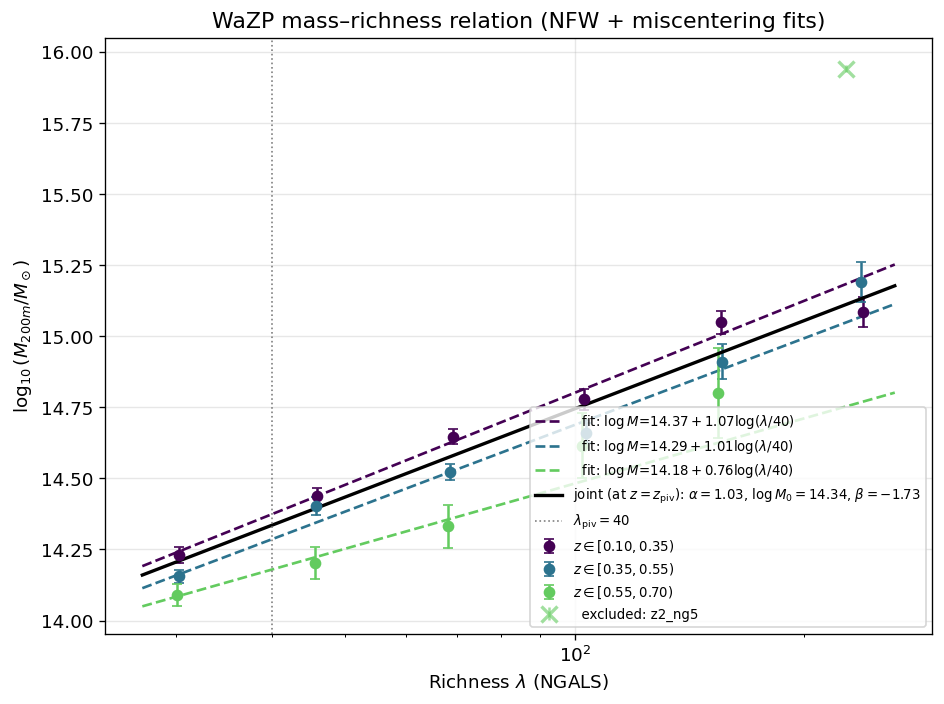

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
lam_smooth = np.geomspace(lam_arr.min()*0.9, lam_arr.max()*1.1, 100)
for zb in range(3):
    sel_all = (zbin_arr == zb)
    sel_fit = sel_all & keep
    sel_exc = sel_all & ~keep
    if not sel_all.any(): continue
    col = colors[zb*2]
    ax.errorbar(lam_arr[sel_fit], logM[sel_fit], yerr=sigM[sel_fit],
                fmt='o', ms=6, capsize=3, color=col,
                label=rf'$z\in[{z_edges[zb]:.2f},{z_edges[zb+1]:.2f})$')
    # Show excluded points as open markers
    if sel_exc.any():
        ax.errorbar(lam_arr[sel_exc], logM[sel_exc], yerr=sigM[sel_exc],
                    fmt='x', ms=10, mew=2, color=col, alpha=0.6,
                    label=(f'  excluded: ' +
                           ', '.join(names[sel_exc])))
    if zb in per_z_fits:
        p = per_z_fits[zb]
        ax.plot(lam_smooth,
                p['logM0'] + p['alpha']*np.log10(lam_smooth/LAM_PIV),
                '--', color=col, lw=1.6,
                label=(rf'  fit: $\log M\!=\!{p["logM0"]:.2f}+'
                       rf'{p["alpha"]:.2f}\log(\lambda/{LAM_PIV:.0f})$'))

ax.plot(lam_smooth,
        joint['logM0'] + joint['alpha']*np.log10(lam_smooth/LAM_PIV),
        '-', color='k', lw=2.0,
        label=(rf'joint (at $z=z_{{\rm piv}}$): '
               rf'$\alpha={joint["alpha"]:.2f}$, '
               rf'$\log M_0={joint["logM0"]:.2f}$, '
               rf'$\beta={joint["beta"]:.2f}$'))

ax.axvline(LAM_PIV, color='grey', ls=':', lw=1.0, label=rf'$\lambda_{{\rm piv}}={LAM_PIV:.0f}$')
ax.set_xscale('log')
ax.set_xlabel(r'Richness $\lambda$ (NGALS)')
ax.set_ylabel(r'$\log_{10}(M_{200m}/M_\odot)$')
ax.set_title('WaZP mass–richness relation (NFW + miscentering fits)')
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()